# SSC Result Analysis


DATA LOADED
     Roll                       Name       Group  Gender Class_Teacher Result   GPA  Bangla  English  Mathematics   BGS  Physics  Chemistry  Biology  ICT  Physical_Education  Carrer_Education  \
0  105239               Sheikh Talha     Science    Male     Dr. Jatka   PASS  4.00     126      136           47  62.0     72.0       71.0     85.0   43                48.0              48.0   
1  105240              Tahia Sultana     Science  Female     Dr. Jatka   PASS  4.22     133      102           55  89.0     62.0       67.0     79.0   43                48.0              48.0   
2  105241  Kazi Sadia Sultana Mahima     Science  Female     Dr. Jatka   PASS  4.11     116      105           61  84.0     67.0       71.0     77.0   45                48.0              48.0   
3  105243              Toslima Begum     Science  Female     Dr. Jatka   PASS  3.78     112       94           41  82.0     61.0       64.0     78.0   44                48.0              48.0   
4  105247    

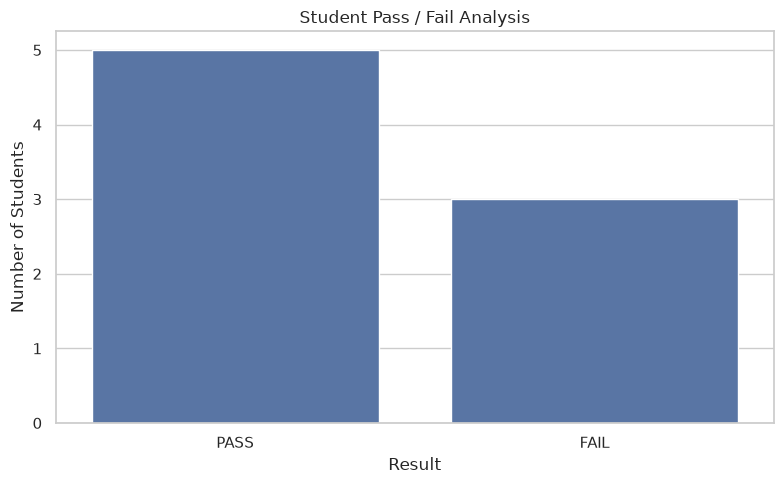

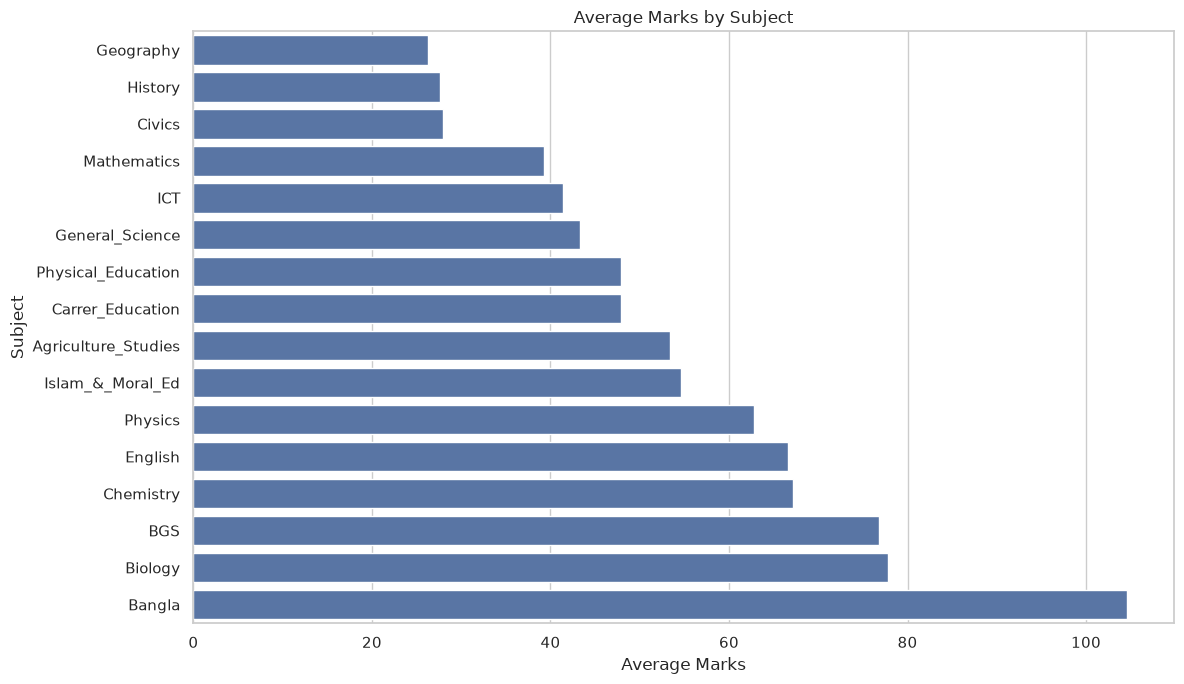

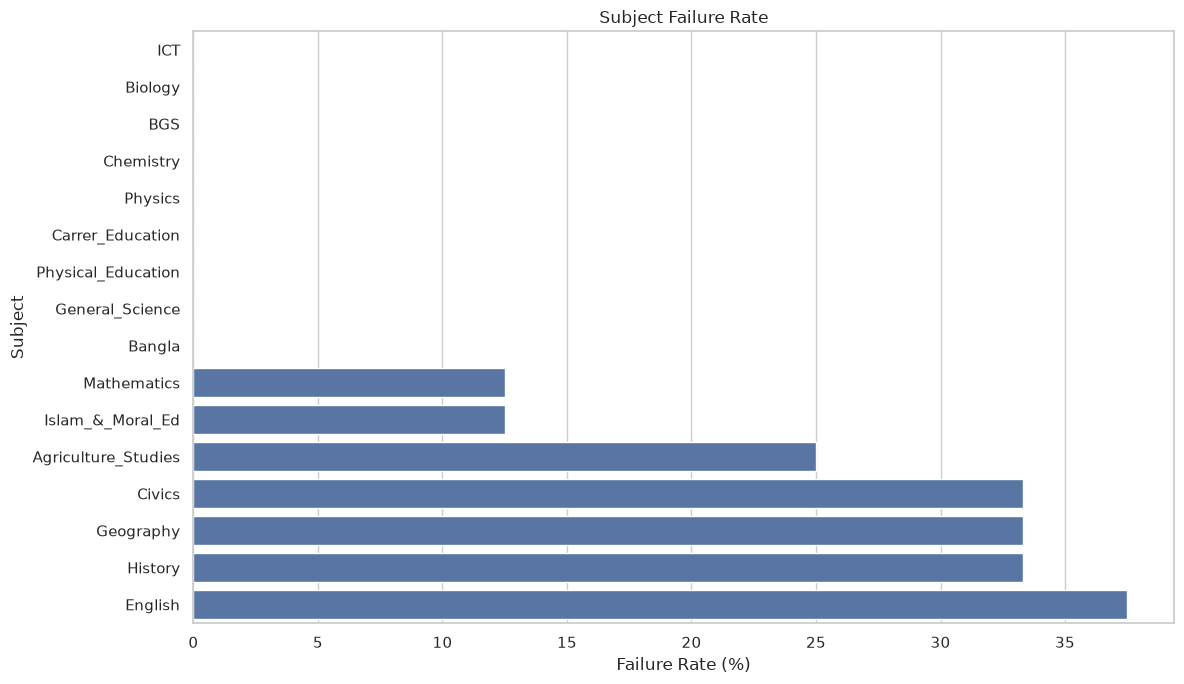

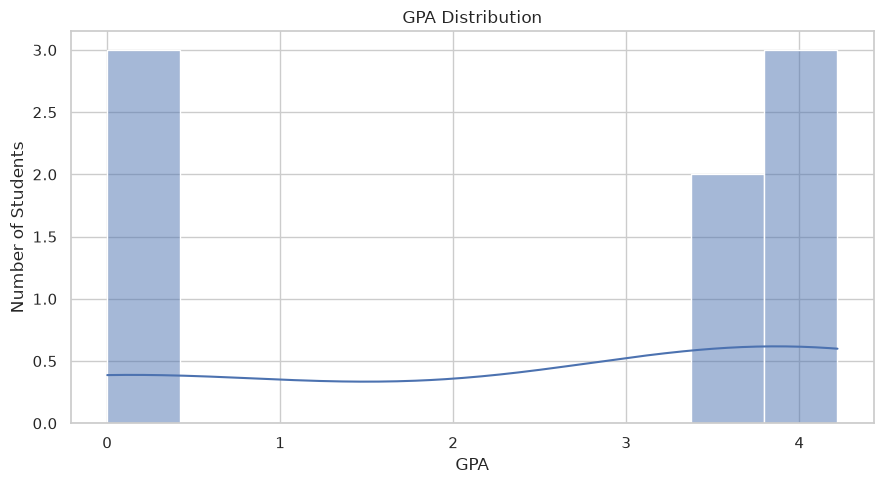

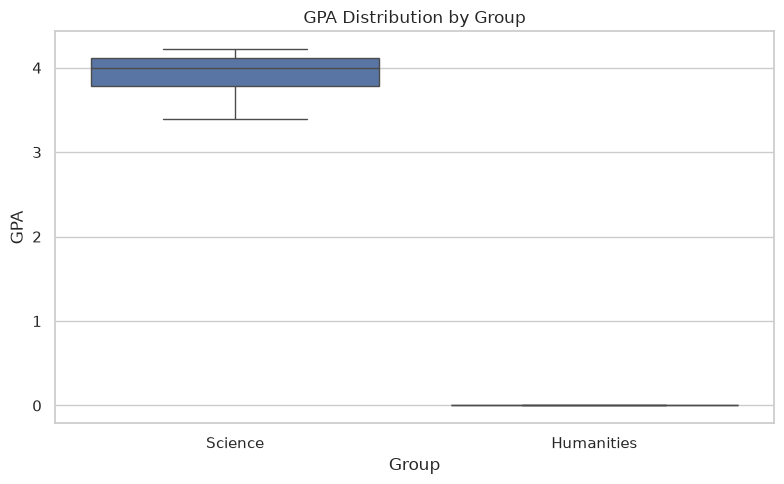

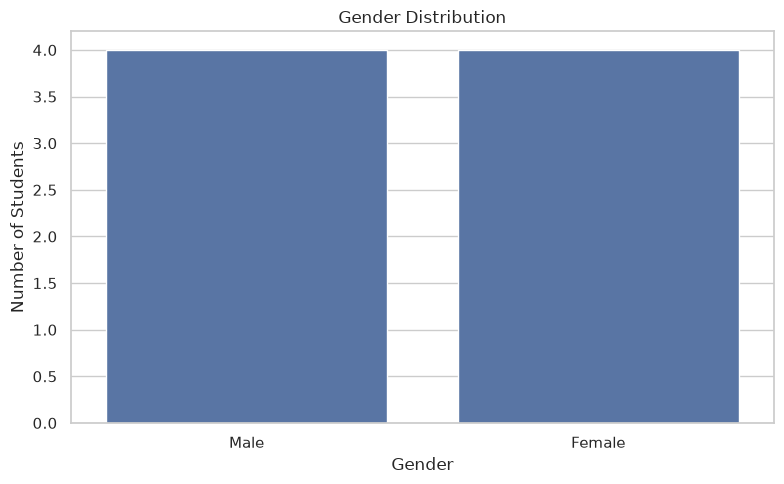

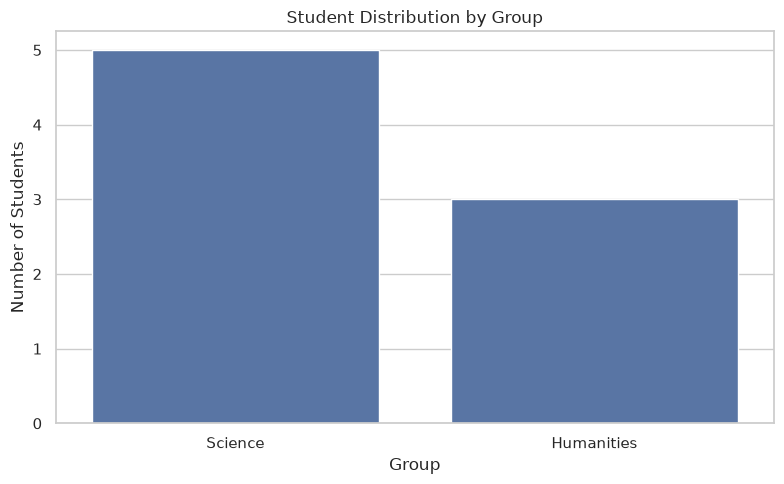

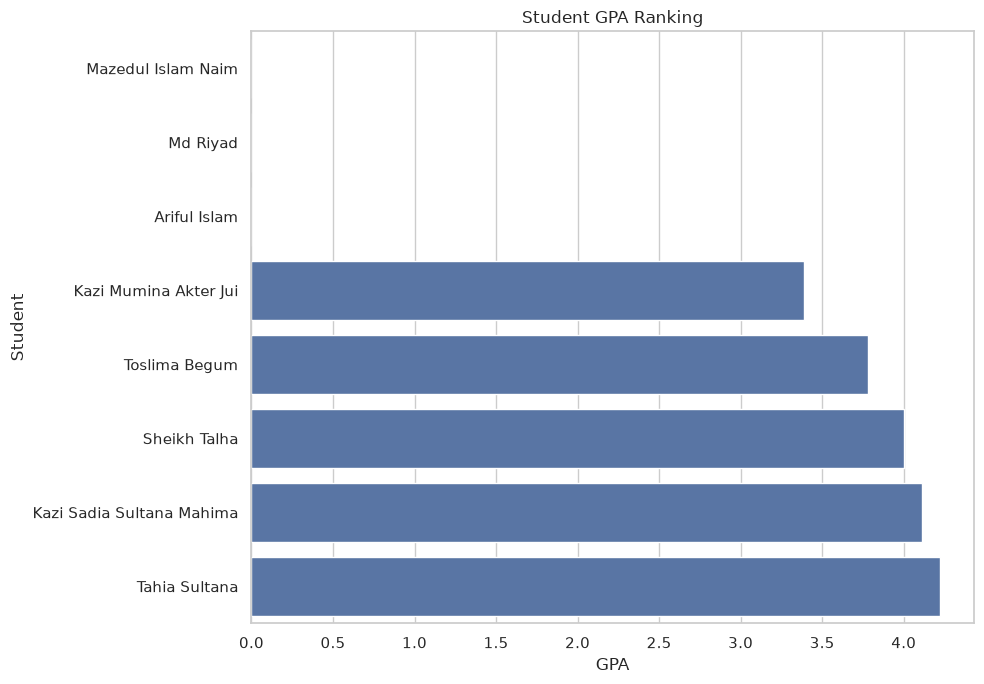


ANALYSIS COMPLETE
Excel file created: ssc_results_2026_analysis.xlsx
Location: /Data/Programming/Phitron/AI Programming With Python/Practise/ssc_results_2026_analysis.xlsx


In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# SETTINGS
# ============================================================

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

# Output Excel file
excel_filename = "ssc_results_2026_analysis.xlsx"


# ============================================================
# 1. RAW DATA
# ============================================================

csv_raw = """
Roll,Name,Group,Gender,Class Teacher,Result,GPA,Bangla,English,Mathematics,BGS,Physics,Chemistry,Biology,ICT,Physical Education ,Carrer Education,General Science,Agriculture Studies,Islam & Moral Ed,Geography,Civics,History
105239,Sheikh Talha,Science,Male,Dr. Jatka,PASS,4,126,136,47,62,72,71,85,43,48,48,,79,69,,,
105240,Tahia Sultana,Science,Female,Dr. Jatka,PASS,4.22,133,102,55,89,62,67,79,43,48,48,,81,83,,,
105241,Kazi Sadia Sultana Mahima,Science,Female,Dr. Jatka,PASS,4.11,116,105,61,84,67,71,77,45,48,48,,73,79,,,
105243,Toslima Begum,Science,Female,Dr. Jatka,PASS,3.78,112,94,41,82,61,64,78,44,48,48,,70,79,,,
105247,Kazi Mumina Akter Jui,Science,Female,Dr. Jatka,PASS,3.39,109,96,42,67,52,63,70,45,48,48,,69,52,,,
308975,Ariful Islam,Humanities,Male,Dr. Jatka,FAIL,0,75,0,34,,,,,37,,,39,0,0,45,0,0
308026,Md Riyad,Humanities,Male,Dr. Jatka,FAIL,0,76,0,34,,,,,37,47,47,45,55,39,34,47,45
308927,Mazedul Islam Naim,Humanities,Male,Dr. Jatka,FAIL,0,90,0,0,,,,,37,48,48,46,0,36,0,37,38
"""

df = pd.read_csv(io.StringIO(csv_raw))

# Clean column names
df.columns = df.columns.str.strip().str.replace(" ", "_")

# Make names easier to work with
df["Roll"] = df["Roll"].astype(str)
df["GPA"] = pd.to_numeric(df["GPA"], errors="coerce")

print("=" * 80)
print("DATA LOADED")
print("=" * 80)
print(df)
print("\nShape:", df.shape)


# ============================================================
# 2. DEFINE SUBJECTS
# ============================================================

# These are the columns that represent student subjects.
subject_columns = [
    "Bangla",
    "English",
    "Mathematics",
    "BGS",
    "Physics",
    "Chemistry",
    "Biology",
    "ICT",
    "Physical_Education",
    "Carrer_Education",
    "General_Science",
    "Agriculture_Studies",
    "Islam_&_Moral_Ed",
    "Geography",
    "Civics",
    "History",
]

# Only keep subjects that actually exist in the dataset
subject_columns = [subject for subject in subject_columns if subject in df.columns]

# Convert subject marks to numeric
for subject in subject_columns:
    df[subject] = pd.to_numeric(df[subject], errors="coerce")


# ============================================================
# 3. PASS MARK
# ============================================================

PASS_MARK = 33


# ============================================================
# 4. STUDENT MASTER TABLE
# ============================================================

master_columns = ["Roll", "Name", "Group", "Gender", "Class_Teacher", "Result", "GPA"]

student_master = df[master_columns].copy()

student_master["Status"] = student_master["Result"].str.upper()

student_master = student_master.sort_values(by=["Group", "Roll"]).reset_index(drop=True)

print("\n" + "=" * 80)
print("1. STUDENT MASTER TABLE")
print("=" * 80)
print(student_master)


# ============================================================
# 5. PER-STUDENT PERFORMANCE
# ============================================================

performance = df[master_columns].copy()

# Total subjects with available marks
performance["Subjects_Attempted"] = df[subject_columns].notna().sum(axis=1)

# Total marks
performance["Total_Marks"] = df[subject_columns].sum(axis=1, skipna=True)

# Average marks
performance["Average_Marks"] = df[subject_columns].mean(axis=1, skipna=True)

# Highest mark
performance["Highest_Mark"] = df[subject_columns].max(axis=1, skipna=True)

# Lowest mark
performance["Lowest_Mark"] = df[subject_columns].min(axis=1, skipna=True)

# Number of failed subjects
performance["Failed_Subjects"] = (
    df[subject_columns].lt(PASS_MARK).fillna(False).sum(axis=1)
)

# Number of passed subjects
performance["Passed_Subjects"] = (
    df[subject_columns].ge(PASS_MARK).fillna(False).sum(axis=1)
)

# Subject pass percentage
performance["Subject_Pass_Rate_%"] = (
    performance["Passed_Subjects"] / performance["Subjects_Attempted"] * 100
).round(2)

# Best subject
performance["Best_Subject"] = df[subject_columns].idxmax(axis=1, skipna=True)

# Weakest subject
performance["Weakest_Subject"] = df[subject_columns].idxmin(axis=1, skipna=True)

performance["Average_Marks"] = performance["Average_Marks"].round(2)

print("\n" + "=" * 80)
print("2. PER-STUDENT PERFORMANCE")
print("=" * 80)
print(performance)


# ============================================================
# 6. OVERALL STUDENT STATISTICS
# ============================================================

total_students = len(df)

passed_students = df["Result"].str.upper().eq("PASS").sum()

failed_students = df["Result"].str.upper().eq("FAIL").sum()

pass_rate = passed_students / total_students * 100 if total_students > 0 else 0

fail_rate = failed_students / total_students * 100 if total_students > 0 else 0

overall_statistics = pd.DataFrame(
    {
        "Statistic": [
            "Total Students",
            "Passed Students",
            "Failed Students",
            "Pass Rate (%)",
            "Fail Rate (%)",
            "Average GPA",
            "Highest GPA",
            "Lowest GPA",
            "Average Marks",
            "Highest Individual Mark",
            "Lowest Individual Mark",
        ],
        "Value": [
            total_students,
            passed_students,
            failed_students,
            round(pass_rate, 2),
            round(fail_rate, 2),
            round(df["GPA"].mean(), 2),
            round(df["GPA"].max(), 2),
            round(df["GPA"].min(), 2),
            round(performance["Average_Marks"].mean(), 2),
            int(df[subject_columns].max().max()),
            int(df[subject_columns].min().min()),
        ],
    }
)

print("\n" + "=" * 80)
print("3. OVERALL STUDENT STATISTICS")
print("=" * 80)
print(overall_statistics)


# ============================================================
# 7. PASS / FAIL ANALYSIS
# ============================================================

result_counts = (
    df["Result"]
    .str.upper()
    .value_counts()
    .rename_axis("Result")
    .reset_index(name="Students")
)

result_counts["Percentage"] = (result_counts["Students"] / total_students * 100).round(
    2
)

print("\n" + "=" * 80)
print("4. PASS / FAIL ANALYSIS")
print("=" * 80)
print(result_counts)


# ============================================================
# 8. SUBJECT-WISE ANALYSIS
# ============================================================

subject_analysis = []

for subject in subject_columns:

    marks = df[subject].dropna()

    attempted = len(marks)

    passed = (marks >= PASS_MARK).sum()
    failed = (marks < PASS_MARK).sum()

    pass_rate_subject = passed / attempted * 100 if attempted > 0 else 0

    fail_rate_subject = failed / attempted * 100 if attempted > 0 else 0

    subject_analysis.append(
        {
            "Subject": subject,
            "Students_With_Marks": attempted,
            "Average_Marks": round(marks.mean(), 2),
            "Highest_Mark": marks.max(),
            "Lowest_Mark": marks.min(),
            "Passed": passed,
            "Failed": failed,
            "Pass_Rate_%": round(pass_rate_subject, 2),
            "Fail_Rate_%": round(fail_rate_subject, 2),
        }
    )

subject_analysis = pd.DataFrame(subject_analysis)

# Weakest subjects first:
# 1. Highest fail rate
# 2. Lowest average marks
subject_analysis = subject_analysis.sort_values(
    by=["Fail_Rate_%", "Average_Marks"], ascending=[False, True]
).reset_index(drop=True)

print("\n" + "=" * 80)
print("5. SUBJECT-WISE ANALYSIS — WEAKEST FIRST")
print("=" * 80)
print(subject_analysis)


# ============================================================
# 9. SUBJECT-WISE GRADE DISTRIBUTION
# ============================================================


def get_grade(mark):
    if pd.isna(mark):
        return "N/A"

    if mark >= 80:
        return "A+"
    elif mark >= 70:
        return "A"
    elif mark >= 60:
        return "A-"
    elif mark >= 50:
        return "B"
    elif mark >= 40:
        return "C"
    elif mark >= 33:
        return "D"
    else:
        return "F"


grade_distribution = []

for subject in subject_columns:

    grades = df[subject].apply(get_grade)

    counts = grades.value_counts()

    row = {"Subject": subject}

    for grade in ["A+", "A", "A-", "B", "C", "D", "F"]:
        row[grade] = counts.get(grade, 0)

    grade_distribution.append(row)

grade_distribution = pd.DataFrame(grade_distribution)

print("\n" + "=" * 80)
print("6. SUBJECT-WISE GRADE DISTRIBUTION")
print("=" * 80)
print(grade_distribution)


# ============================================================
# 10. FAILED STUDENTS & FAILED SUBJECTS
# ============================================================

failed_records = []

for _, student in df.iterrows():

    for subject in subject_columns:

        mark = student[subject]

        if pd.notna(mark) and mark < PASS_MARK:

            failed_records.append(
                {
                    "Roll": student["Roll"],
                    "Name": student["Name"],
                    "Group": student["Group"],
                    "Gender": student["Gender"],
                    "Subject": subject,
                    "Mark": mark,
                    "Required_Mark": PASS_MARK,
                    "Short_By": PASS_MARK - mark,
                }
            )

failed_students_subjects = pd.DataFrame(failed_records)

print("\n" + "=" * 80)
print("7. FAILED STUDENTS & FAILED SUBJECTS")
print("=" * 80)
print(failed_students_subjects)


# ============================================================
# 11. STUDENT RANKING BY GPA
# ============================================================

ranking = df[["Roll", "Name", "Group", "Gender", "Result", "GPA"]].copy()

# Rank highest GPA first
ranking["Rank"] = ranking["GPA"].rank(method="min", ascending=False).astype(int)

ranking = ranking.sort_values(by=["Rank", "Name"]).reset_index(drop=True)

# Put Rank first
ranking = ranking[["Rank", "Roll", "Name", "Group", "Gender", "Result", "GPA"]]

print("\n" + "=" * 80)
print("8. STUDENT RANKING BY GPA")
print("=" * 80)
print(ranking)


# ============================================================
# 12. GROUP-WISE ANALYSIS
# ============================================================

group_analysis = (
    df.groupby("Group")
    .agg(
        Students=("Roll", "count"),
        Male=("Gender", lambda x: (x.str.upper() == "MALE").sum()),
        Female=("Gender", lambda x: (x.str.upper() == "FEMALE").sum()),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_analysis["Pass_Rate_%"] = (
    group_analysis["Passed"] / group_analysis["Students"] * 100
).round(2)

group_analysis["Fail_Rate_%"] = (
    group_analysis["Failed"] / group_analysis["Students"] * 100
).round(2)

group_analysis["Average_GPA"] = group_analysis["Average_GPA"].round(2)

print("\n" + "=" * 80)
print("9. GROUP-WISE ANALYSIS")
print("=" * 80)
print(group_analysis)


# ============================================================
# 13. GROUP + GENDER ANALYSIS
# ============================================================

group_gender_analysis = (
    df.groupby(["Group", "Gender"])
    .agg(
        Students=("Roll", "count"),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_gender_analysis["Pass_Rate_%"] = (
    group_gender_analysis["Passed"] / group_gender_analysis["Students"] * 100
).round(2)

group_gender_analysis["Average_GPA"] = group_gender_analysis["Average_GPA"].round(2)

print("\n" + "=" * 80)
print("GROUP + GENDER ANALYSIS")
print("=" * 80)
print(group_gender_analysis)


# ============================================================
# 14. BEST & WEAKEST SUBJECT PER STUDENT
# ============================================================

best_weakest = df[["Roll", "Name", "Group", "Gender", "GPA"]].copy()

best_weakest["Best_Subject"] = df[subject_columns].idxmax(axis=1, skipna=True)

best_weakest["Best_Mark"] = df[subject_columns].max(axis=1, skipna=True)

best_weakest["Weakest_Subject"] = df[subject_columns].idxmin(axis=1, skipna=True)

best_weakest["Weakest_Mark"] = df[subject_columns].min(axis=1, skipna=True)

print("\n" + "=" * 80)
print("10. BEST & WEAKEST SUBJECT PER STUDENT")
print("=" * 80)
print(best_weakest)


# ============================================================
# 15. SUBJECT MARK MATRIX
# ============================================================

subject_mark_matrix = df[["Roll", "Name", "Group", "Gender"] + subject_columns].copy()

print("\n" + "=" * 80)
print("SUBJECT MARK MATRIX")
print("=" * 80)
print(subject_mark_matrix)


# ============================================================
# 16. TOP STUDENTS
# ============================================================

top_students = ranking.head(10).copy()

print("\n" + "=" * 80)
print("TOP 10 STUDENTS")
print("=" * 80)
print(top_students)


# ============================================================
# 17. WEAKEST SUBJECTS
# ============================================================

weakest_subjects = subject_analysis[
    [
        "Subject",
        "Average_Marks",
        "Highest_Mark",
        "Lowest_Mark",
        "Passed",
        "Failed",
        "Pass_Rate_%",
        "Fail_Rate_%",
    ]
].copy()

print("\n" + "=" * 80)
print("WEAKEST SUBJECTS")
print("=" * 80)
print(weakest_subjects)


# ============================================================
# 18. CHART 1 — PASS / FAIL
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(data=result_counts, x="Result", y="Students")

plt.title("Student Pass / Fail Analysis")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


# ============================================================
# 19. CHART 2 — AVERAGE MARKS BY SUBJECT
# ============================================================

plot_subjects = subject_analysis.sort_values("Average_Marks", ascending=True)

plt.figure(figsize=(12, 7))

sns.barplot(data=plot_subjects, x="Average_Marks", y="Subject")

plt.title("Average Marks by Subject")
plt.xlabel("Average Marks")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()


# ============================================================
# 20. CHART 3 — SUBJECT FAILURE RATE
# ============================================================

plot_fail = subject_analysis.sort_values("Fail_Rate_%", ascending=True)

plt.figure(figsize=(12, 7))

sns.barplot(data=plot_fail, x="Fail_Rate_%", y="Subject")

plt.title("Subject Failure Rate")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()


# ============================================================
# 21. CHART 4 — GPA DISTRIBUTION
# ============================================================

plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="GPA", bins=10, kde=True)

plt.title("GPA Distribution")
plt.xlabel("GPA")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


# ============================================================
# 22. CHART 5 — GPA BY GROUP
# ============================================================

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Group", y="GPA")

plt.title("GPA Distribution by Group")
plt.xlabel("Group")
plt.ylabel("GPA")

plt.tight_layout()
plt.show()


# ============================================================
# 23. CHART 6 — GENDER DISTRIBUTION
# ============================================================

gender_counts = df["Gender"].value_counts().reset_index()

gender_counts.columns = ["Gender", "Students"]

plt.figure(figsize=(8, 5))

sns.barplot(data=gender_counts, x="Gender", y="Students")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


# ============================================================
# 24. CHART 7 — GROUP DISTRIBUTION
# ============================================================

group_counts = df["Group"].value_counts().reset_index()

group_counts.columns = ["Group", "Students"]

plt.figure(figsize=(8, 5))

sns.barplot(data=group_counts, x="Group", y="Students")

plt.title("Student Distribution by Group")
plt.xlabel("Group")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()


# ============================================================
# 25. CHART 8 — STUDENT GPA RANKING
# ============================================================

ranking_plot = ranking.sort_values("GPA", ascending=True)

plt.figure(figsize=(10, 7))

sns.barplot(data=ranking_plot, x="GPA", y="Name")

plt.title("Student GPA Ranking")
plt.xlabel("GPA")
plt.ylabel("Student")

plt.tight_layout()
plt.show()


# ============================================================
# 26. SAVE EVERYTHING TO EXCEL
# ============================================================

with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:

    df.to_excel(writer, sheet_name="Raw Data", index=False)

    student_master.to_excel(writer, sheet_name="Student Master", index=False)

    performance.to_excel(writer, sheet_name="Student Performance", index=False)

    overall_statistics.to_excel(writer, sheet_name="Overall Statistics", index=False)

    result_counts.to_excel(writer, sheet_name="Pass Fail Analysis", index=False)

    subject_analysis.to_excel(writer, sheet_name="Subject Analysis", index=False)

    grade_distribution.to_excel(writer, sheet_name="Grade Distribution", index=False)

    failed_students_subjects.to_excel(writer, sheet_name="Failed Subjects", index=False)

    ranking.to_excel(writer, sheet_name="GPA Ranking", index=False)

    group_analysis.to_excel(writer, sheet_name="Group Analysis", index=False)

    group_gender_analysis.to_excel(
        writer, sheet_name="Group Gender Analysis", index=False
    )

    best_weakest.to_excel(writer, sheet_name="Best Weakest Subject", index=False)

    subject_mark_matrix.to_excel(writer, sheet_name="Subject Marks", index=False)

print("\n" + "=" * 80)
print("ANALYSIS COMPLETE")
print("=" * 80)
print(f"Excel file created: {excel_filename}")
print(f"Location: {os.path.abspath(excel_filename)}")


                    STUDENT RESULT ANALYSIS

Dataset shape:
Rows    : 8
Columns : 23


1. STUDENT MASTER TABLE
Rows: 8 | Columns: 8

  Roll                      Name      Group Gender Class_Teacher Result  GPA Status
308026                  Md Riyad Humanities   Male     Dr. Jatka   FAIL 0.00   FAIL
308927        Mazedul Islam Naim Humanities   Male     Dr. Jatka   FAIL 0.00   FAIL
308975              Ariful Islam Humanities   Male     Dr. Jatka   FAIL 0.00   FAIL
105239              Sheikh Talha    Science   Male     Dr. Jatka   PASS 4.00   PASS
105240             Tahia Sultana    Science Female     Dr. Jatka   PASS 4.22   PASS
105241 Kazi Sadia Sultana Mahima    Science Female     Dr. Jatka   PASS 4.11   PASS
105243             Toslima Begum    Science Female     Dr. Jatka   PASS 3.78   PASS
105247     Kazi Mumina Akter Jui    Science Female     Dr. Jatka   PASS 3.39   PASS


2. PER-STUDENT PERFORMANCE
Rows: 8 | Columns: 16

  Roll                      Name      Group Gender Result 

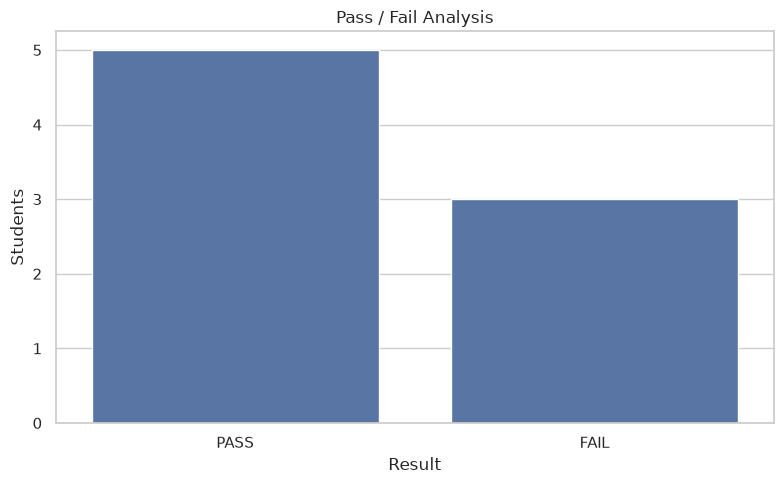

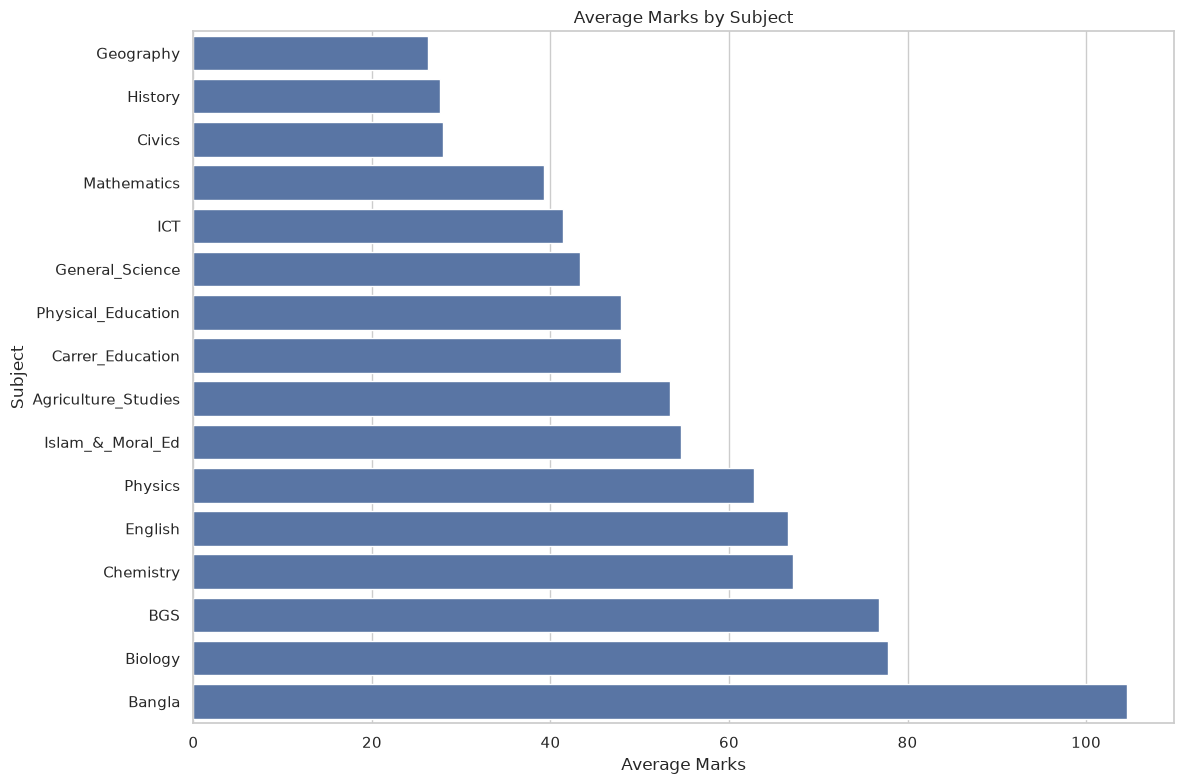

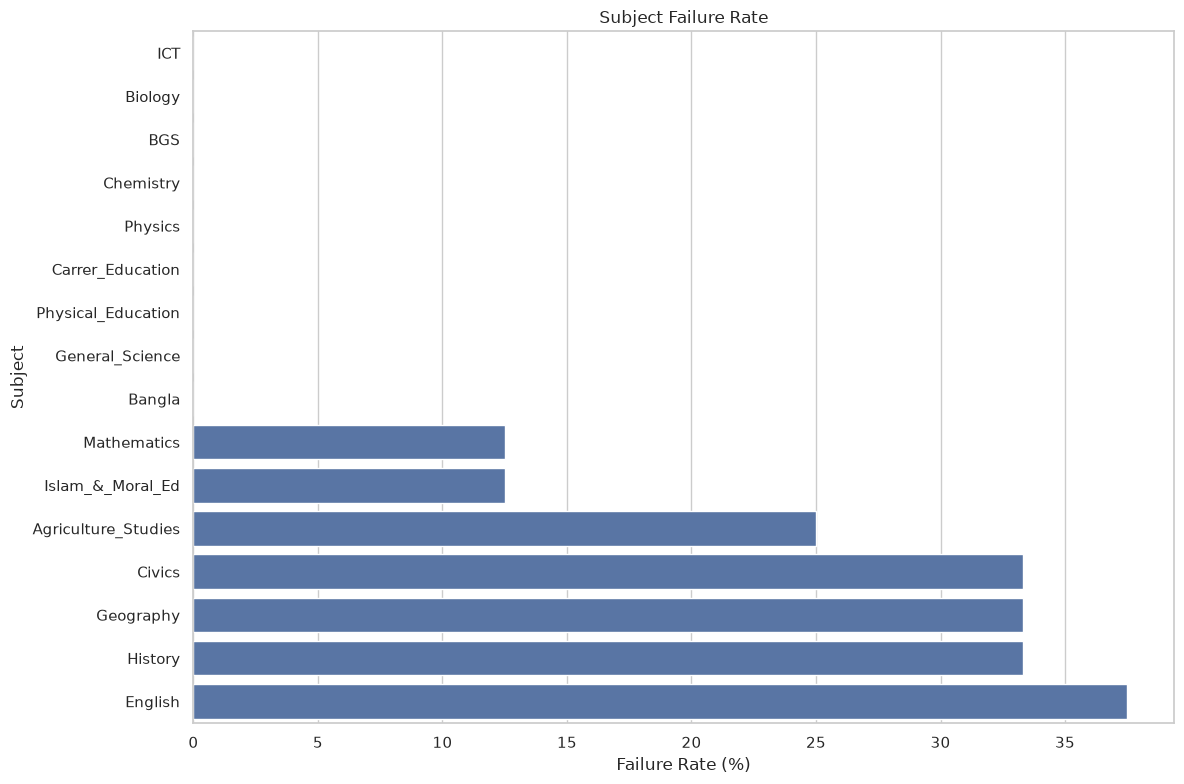

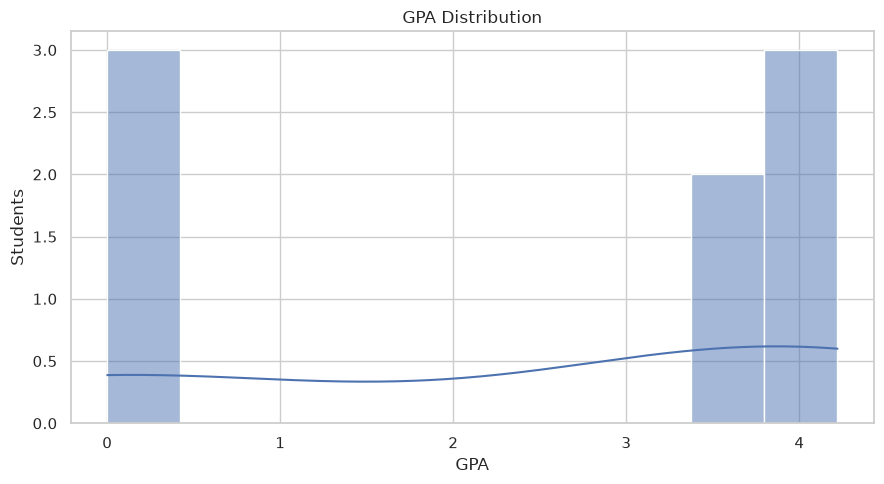

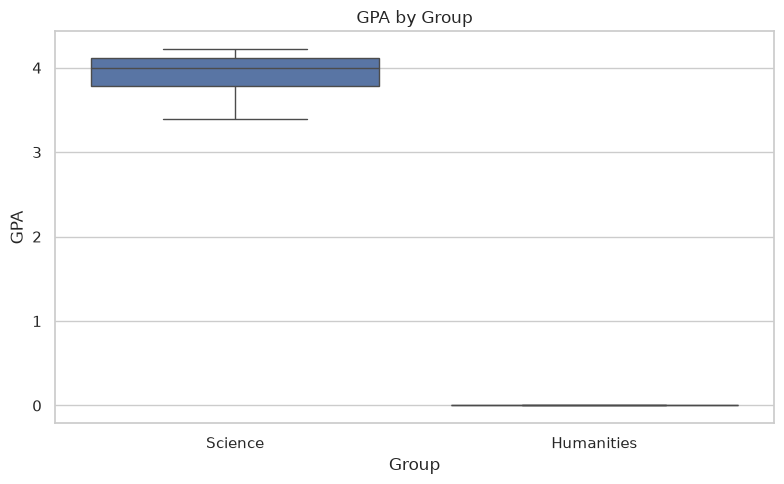

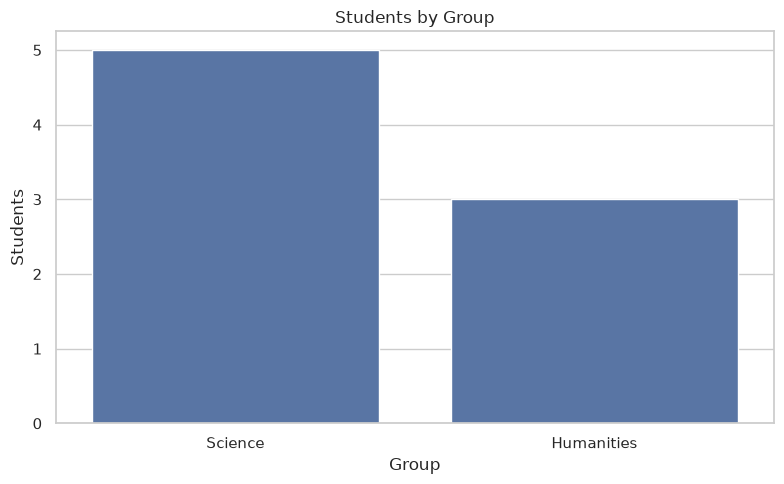

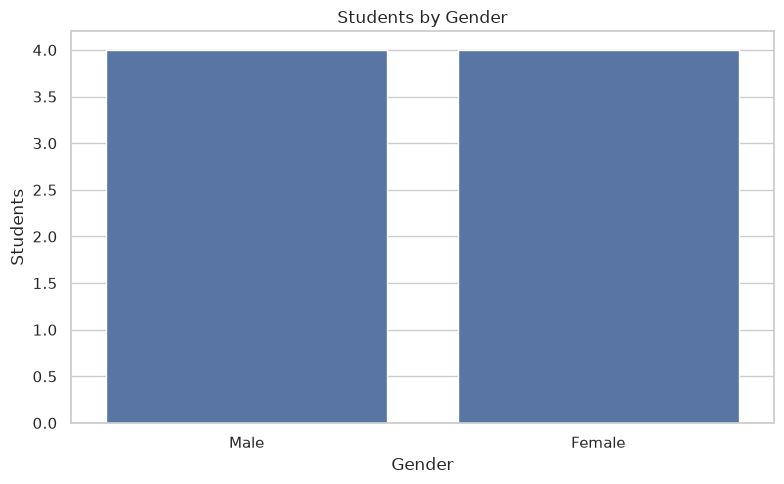


EXCEL EXPORT SKIPPED

All analysis has been displayed above.

If you want the Excel file later, simply change:

    EXPORT_TO_EXCEL = False

to:

    EXPORT_TO_EXCEL = True

and run the notebook again.



In [2]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)


# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(io.StringIO(csv_raw))

# Clean column names
df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False)

# Convert numeric columns
df["GPA"] = pd.to_numeric(df["GPA"], errors="coerce")

print("\n" + "=" * 100)
print("                    STUDENT RESULT ANALYSIS")
print("=" * 100)

print("\nDataset shape:")
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")


# ============================================================
# SUBJECT LIST
# ============================================================

subject_columns = [
    "Bangla",
    "English",
    "Mathematics",
    "BGS",
    "Physics",
    "Chemistry",
    "Biology",
    "ICT",
    "Physical_Education",
    "Carrer_Education",
    "General_Science",
    "Agriculture_Studies",
    "Islam_&_Moral_Ed",
    "Geography",
    "Civics",
    "History",
]

# Only subjects that exist
subject_columns = [col for col in subject_columns if col in df.columns]

# Convert subject marks to numbers
for subject in subject_columns:
    df[subject] = pd.to_numeric(df[subject], errors="coerce")

PASS_MARK = 33


# ============================================================
# HELPER FUNCTION FOR OUTPUT
# ============================================================


def show_table(title, dataframe):
    print("\n")
    print("=" * 100)
    print(title)
    print("=" * 100)

    print(f"Rows: {len(dataframe)} | Columns: {len(dataframe.columns)}")
    print()

    print(dataframe.to_string(index=False))


# ============================================================
# 1. STUDENT MASTER TABLE
# ============================================================

student_master = df[
    ["Roll", "Name", "Group", "Gender", "Class_Teacher", "Result", "GPA"]
].copy()

student_master["Status"] = student_master["Result"].str.upper()

student_master = student_master.sort_values(["Group", "Roll"])

show_table("1. STUDENT MASTER TABLE", student_master)


# ============================================================
# 2. PER-STUDENT PERFORMANCE
# ============================================================

performance = df[["Roll", "Name", "Group", "Gender", "Result", "GPA"]].copy()

performance["Subjects_Attempted"] = df[subject_columns].notna().sum(axis=1)

performance["Total_Marks"] = df[subject_columns].sum(axis=1, skipna=True)

performance["Average_Marks"] = df[subject_columns].mean(axis=1, skipna=True).round(2)

performance["Highest_Mark"] = df[subject_columns].max(axis=1, skipna=True)

performance["Lowest_Mark"] = df[subject_columns].min(axis=1, skipna=True)

performance["Passed_Subjects"] = df[subject_columns].ge(PASS_MARK).sum(axis=1)

performance["Failed_Subjects"] = df[subject_columns].lt(PASS_MARK).sum(axis=1)

performance["Subject_Pass_Rate_%"] = (
    performance["Passed_Subjects"] / performance["Subjects_Attempted"] * 100
).round(2)

performance["Best_Subject"] = df[subject_columns].idxmax(axis=1)

performance["Weakest_Subject"] = df[subject_columns].idxmin(axis=1)

show_table("2. PER-STUDENT PERFORMANCE", performance)


# ============================================================
# 3. OVERALL STUDENT STATISTICS
# ============================================================

total_students = len(df)

passed_students = df["Result"].str.upper().eq("PASS").sum()

failed_students = df["Result"].str.upper().eq("FAIL").sum()

pass_rate = passed_students / total_students * 100

fail_rate = failed_students / total_students * 100

overall_statistics = pd.DataFrame(
    {
        "Statistic": [
            "Total Students",
            "Passed Students",
            "Failed Students",
            "Pass Rate (%)",
            "Fail Rate (%)",
            "Average GPA",
            "Highest GPA",
            "Lowest GPA",
            "Average Marks",
            "Highest Mark",
            "Lowest Mark",
        ],
        "Value": [
            total_students,
            passed_students,
            failed_students,
            round(pass_rate, 2),
            round(fail_rate, 2),
            round(df["GPA"].mean(), 2),
            round(df["GPA"].max(), 2),
            round(df["GPA"].min(), 2),
            round(performance["Average_Marks"].mean(), 2),
            df[subject_columns].max().max(),
            df[subject_columns].min().min(),
        ],
    }
)

show_table("3. OVERALL STUDENT STATISTICS", overall_statistics)


# ============================================================
# 4. PASS / FAIL ANALYSIS
# ============================================================

pass_fail = (
    df["Result"]
    .str.upper()
    .value_counts()
    .rename_axis("Result")
    .reset_index(name="Students")
)

pass_fail["Percentage_%"] = (pass_fail["Students"] / total_students * 100).round(2)

show_table("4. PASS / FAIL ANALYSIS", pass_fail)


# ============================================================
# 5. SUBJECT-WISE ANALYSIS
# ============================================================

subject_rows = []

for subject in subject_columns:

    marks = df[subject].dropna()

    total = len(marks)

    passed = (marks >= PASS_MARK).sum()
    failed = (marks < PASS_MARK).sum()

    subject_rows.append(
        {
            "Subject": subject,
            "Students": total,
            "Average": round(marks.mean(), 2),
            "Highest": marks.max(),
            "Lowest": marks.min(),
            "Passed": passed,
            "Failed": failed,
            "Pass_Rate_%": round(passed / total * 100, 2),
            "Fail_Rate_%": round(failed / total * 100, 2),
        }
    )

subject_analysis = pd.DataFrame(subject_rows)

# Weakest subjects first
subject_analysis = subject_analysis.sort_values(
    ["Fail_Rate_%", "Average"], ascending=[False, True]
).reset_index(drop=True)

show_table("5. SUBJECT-WISE ANALYSIS — WEAKEST FIRST", subject_analysis)


# ============================================================
# 6. SUBJECT-WISE GRADE DISTRIBUTION
# ============================================================


def grade(mark):

    if pd.isna(mark):
        return "N/A"

    if mark >= 80:
        return "A+"
    elif mark >= 70:
        return "A"
    elif mark >= 60:
        return "A-"
    elif mark >= 50:
        return "B"
    elif mark >= 40:
        return "C"
    elif mark >= 33:
        return "D"
    else:
        return "F"


grade_rows = []

for subject in subject_columns:

    grades = df[subject].apply(grade)

    grade_rows.append(
        {
            "Subject": subject,
            "A+": (grades == "A+").sum(),
            "A": (grades == "A").sum(),
            "A-": (grades == "A-").sum(),
            "B": (grades == "B").sum(),
            "C": (grades == "C").sum(),
            "D": (grades == "D").sum(),
            "F": (grades == "F").sum(),
        }
    )

grade_distribution = pd.DataFrame(grade_rows)

show_table("6. SUBJECT-WISE GRADE DISTRIBUTION", grade_distribution)


# ============================================================
# 7. FAILED STUDENTS & FAILED SUBJECTS
# ============================================================

failed_rows = []

for _, student in df.iterrows():

    for subject in subject_columns:

        mark = student[subject]

        if pd.notna(mark) and mark < PASS_MARK:

            failed_rows.append(
                {
                    "Roll": student["Roll"],
                    "Name": student["Name"],
                    "Group": student["Group"],
                    "Gender": student["Gender"],
                    "Subject": subject,
                    "Mark": mark,
                    "Pass_Mark": PASS_MARK,
                    "Short_By": PASS_MARK - mark,
                }
            )

failed_subjects = pd.DataFrame(failed_rows)

show_table("7. FAILED STUDENTS & FAILED SUBJECTS", failed_subjects)


# ============================================================
# 8. STUDENT RANKING BY GPA
# ============================================================

ranking = df[["Roll", "Name", "Group", "Gender", "Result", "GPA"]].copy()

ranking["Rank"] = ranking["GPA"].rank(method="min", ascending=False).astype(int)

ranking = ranking.sort_values(["Rank", "Name"])

ranking = ranking[["Rank", "Roll", "Name", "Group", "Gender", "Result", "GPA"]]

show_table("8. STUDENT RANKING BY GPA", ranking)


# ============================================================
# 9. GROUP-WISE ANALYSIS
# ============================================================

group_analysis = (
    df.groupby("Group")
    .agg(
        Students=("Roll", "count"),
        Male=("Gender", lambda x: (x.str.upper() == "MALE").sum()),
        Female=("Gender", lambda x: (x.str.upper() == "FEMALE").sum()),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_analysis["Average_GPA"] = group_analysis["Average_GPA"].round(2)

group_analysis["Pass_Rate_%"] = (
    group_analysis["Passed"] / group_analysis["Students"] * 100
).round(2)

group_analysis["Fail_Rate_%"] = (
    group_analysis["Failed"] / group_analysis["Students"] * 100
).round(2)

show_table("9. GROUP-WISE ANALYSIS", group_analysis)


# ============================================================
# 10. GROUP + GENDER ANALYSIS
# ============================================================

group_gender = (
    df.groupby(["Group", "Gender"])
    .agg(
        Students=("Roll", "count"),
        Average_GPA=("GPA", "mean"),
        Highest_GPA=("GPA", "max"),
        Lowest_GPA=("GPA", "min"),
        Passed=("Result", lambda x: (x.str.upper() == "PASS").sum()),
        Failed=("Result", lambda x: (x.str.upper() == "FAIL").sum()),
    )
    .reset_index()
)

group_gender["Average_GPA"] = group_gender["Average_GPA"].round(2)

group_gender["Pass_Rate_%"] = (
    group_gender["Passed"] / group_gender["Students"] * 100
).round(2)

show_table("10. GROUP + GENDER ANALYSIS", group_gender)


# ============================================================
# 11. BEST & WEAKEST SUBJECT PER STUDENT
# ============================================================

best_weakest = df[["Roll", "Name", "Group", "Gender", "GPA"]].copy()

best_weakest["Best_Subject"] = df[subject_columns].idxmax(axis=1)

best_weakest["Best_Mark"] = df[subject_columns].max(axis=1)

best_weakest["Weakest_Subject"] = df[subject_columns].idxmin(axis=1)

best_weakest["Weakest_Mark"] = df[subject_columns].min(axis=1)

show_table("11. BEST & WEAKEST SUBJECT PER STUDENT", best_weakest)


# ============================================================
# 12. COMPLETE SUBJECT MARK TABLE
# ============================================================

subject_marks = df[["Roll", "Name", "Group", "Gender"] + subject_columns].copy()

show_table("12. COMPLETE SUBJECT MARK TABLE", subject_marks)


# ============================================================
# 13. TOP STUDENTS
# ============================================================

top_students = ranking.head(10)

show_table("13. TOP 10 STUDENTS BY GPA", top_students)


# ============================================================
# 14. WEAKEST SUBJECTS
# ============================================================

weakest_subjects = subject_analysis[
    [
        "Subject",
        "Average",
        "Highest",
        "Lowest",
        "Passed",
        "Failed",
        "Pass_Rate_%",
        "Fail_Rate_%",
    ]
]

show_table("14. WEAKEST SUBJECTS", weakest_subjects)


# ============================================================
# 15. SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("                         FINAL SUMMARY")
print("=" * 100)

print(f"""
Total Students       : {total_students}
Passed Students      : {passed_students}
Failed Students      : {failed_students}

Overall Pass Rate    : {pass_rate:.2f}%
Overall Fail Rate    : {fail_rate:.2f}%

Average GPA          : {df["GPA"].mean():.2f}
Highest GPA          : {df["GPA"].max():.2f}
Lowest GPA           : {df["GPA"].min():.2f}

Best Student         : {ranking.iloc[0]["Name"]}
Best Student GPA     : {ranking.iloc[0]["GPA"]}

Weakest Subject      : {subject_analysis.iloc[0]["Subject"]}
Weakest Subject
Failure Rate         : {subject_analysis.iloc[0]["Fail_Rate_%"]}%
""")


# ============================================================
# 16. VISUAL ANALYSIS
# ============================================================

# ------------------------------------------------------------
# PASS / FAIL
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(data=pass_fail, x="Result", y="Students")

plt.title("Pass / Fail Analysis")
plt.xlabel("Result")
plt.ylabel("Students")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# SUBJECT AVERAGES
# ------------------------------------------------------------

plot_avg = subject_analysis.sort_values("Average")

plt.figure(figsize=(12, 8))

sns.barplot(data=plot_avg, x="Average", y="Subject")

plt.title("Average Marks by Subject")
plt.xlabel("Average Marks")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# SUBJECT FAILURE RATE
# ------------------------------------------------------------

plot_fail = subject_analysis.sort_values("Fail_Rate_%")

plt.figure(figsize=(12, 8))

sns.barplot(data=plot_fail, x="Fail_Rate_%", y="Subject")

plt.title("Subject Failure Rate")
plt.xlabel("Failure Rate (%)")
plt.ylabel("Subject")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GPA DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.histplot(df["GPA"], bins=10, kde=True)

plt.title("GPA Distribution")
plt.xlabel("GPA")
plt.ylabel("Students")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GPA BY GROUP
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Group", y="GPA")

plt.title("GPA by Group")
plt.xlabel("Group")
plt.ylabel("GPA")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GROUP DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Group")

plt.title("Students by Group")
plt.xlabel("Group")
plt.ylabel("Students")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GENDER DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Gender")

plt.title("Students by Gender")
plt.xlabel("Gender")
plt.ylabel("Students")

plt.tight_layout()
plt.show()


# ============================================================
# 17. OPTIONAL EXCEL EXPORT
# ============================================================

EXPORT_TO_EXCEL = False


if EXPORT_TO_EXCEL:

    excel_filename = "ssc_results_2026_analysis.xlsx"

    with pd.ExcelWriter(excel_filename, engine="openpyxl") as writer:

        df.to_excel(writer, sheet_name="Raw Data", index=False)

        student_master.to_excel(writer, sheet_name="Student Master", index=False)

        performance.to_excel(writer, sheet_name="Student Performance", index=False)

        overall_statistics.to_excel(
            writer, sheet_name="Overall Statistics", index=False
        )

        pass_fail.to_excel(writer, sheet_name="Pass Fail Analysis", index=False)

        subject_analysis.to_excel(writer, sheet_name="Subject Analysis", index=False)

        grade_distribution.to_excel(
            writer, sheet_name="Grade Distribution", index=False
        )

        failed_subjects.to_excel(writer, sheet_name="Failed Subjects", index=False)

        ranking.to_excel(writer, sheet_name="GPA Ranking", index=False)

        group_analysis.to_excel(writer, sheet_name="Group Analysis", index=False)

        group_gender.to_excel(writer, sheet_name="Group Gender", index=False)

        best_weakest.to_excel(writer, sheet_name="Best Weakest", index=False)

        subject_marks.to_excel(writer, sheet_name="Subject Marks", index=False)

    print("\n" + "=" * 100)
    print("EXCEL EXPORT COMPLETE")
    print("=" * 100)
    print(f"File: {os.path.abspath(excel_filename)}")

else:

    print("\n" + "=" * 100)
    print("EXCEL EXPORT SKIPPED")
    print("=" * 100)
    print("""
All analysis has been displayed above.

If you want the Excel file later, simply change:

    EXPORT_TO_EXCEL = False

to:

    EXPORT_TO_EXCEL = True

and run the notebook again.
""")